<a href="https://colab.research.google.com/github/danikarosalyn/3002F26/blob/main/HOPFIELD_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

## Welcome! In this notebook, you'll create a simple Hopfield Network using binary values (0 and 1). You'll visualize the weight matrix and test how the network retrieves stored patterns.



In [2]:
# Cell 1: Imports and setup
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')


In [ ]:
#Try running the below chunk, why are you getting an error? What does this represent? How would you change it to prevent this error?


In [3]:
# Cell 2: 🔧 Define Training Patterns

# EDIT HERE
# Each row = one input/output pair
input_patterns = np.array([
    [1, 0, 1, 0],
    [0, 1, 0, 1],
])

output_patterns = np.array([
    [1, 1, 0, 0],
    [0, 0, 1, 0],
])

assert input_patterns.shape == output_patterns.shape, "Input/output shape mismatch"
n_neurons = input_patterns.shape[1]



In [ ]:
### Questions:

##1. How many patterns are being stored in this network? how do you know what is the input and what is the output being trained?
##2. How many neurons does this network represent?
##3. What happens if you remove one of the outputs and still have 2 inputs? Why would this be the case biologically?
##4. What is the assertion line doing? Why is it there?
##5. What do you think would happen if input and output patterns are the same?

In [4]:
# Cell 3: Convert binary to bipolar form
def to_bipolar(binary_array):
    return 2 * binary_array - 1  # 0→-1, 1→1

def to_binary(bipolar_array):
    return (bipolar_array > 0).astype(int)


In [5]:
# Cell 4: Train the Hopfield network (associative memory)

# Use a modified Hebbian rule: W = sum over (input^T * output)
def train_associative(input_patterns, output_patterns):
    n = input_patterns.shape[1]
    W = np.zeros((n, n))

    for i in range(len(input_patterns)):
        x = to_bipolar(input_patterns[i])
        y = to_bipolar(output_patterns[i])
        W += np.outer(y, x)  # Associative: output * input.T

    np.fill_diagonal(W, 0)  # No self-connection
    return W

W = train_associative(input_patterns, output_patterns)


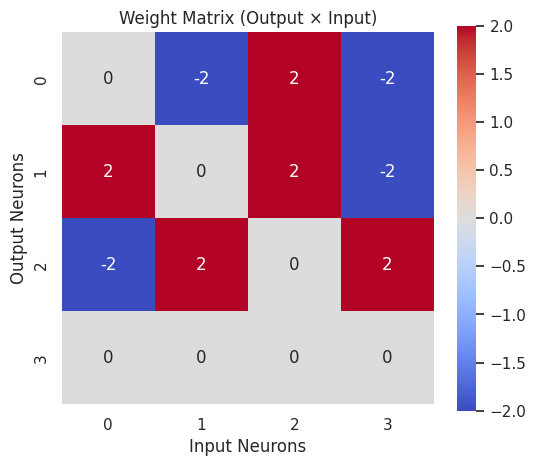

In [6]:
# Cell 5: Visualize the weight matrix
def visualize_weights(W, title="Weight Matrix (Output × Input)"):
    plt.figure(figsize=(6,5))
    sns.heatmap(W, annot=True, cmap='coolwarm', center=0, square=True)
    plt.title(title)
    plt.xlabel("Input Neurons")
    plt.ylabel("Output Neurons")
    plt.show()

visualize_weights(W)


In [1]:
## READ ME: Understanding the Weight Matrix

#The weight matrix `W` encodes the **associations between input and output neurons**:

#-# Each entry `W[i][j]` represents the strength and type of connection **from input neuron `j` to output neuron `i`**.
#- #Positive values mean that when the input neuron `j` is ON (1), it encourages the output neuron `i` to be ON.
#- #Negative values mean the input neuron `j` being ON discourages output neuron `i` from turning ON.
#- #Values close to zero indicate weak or no influence.

#Because we use bipolar form internally (`0 → -1` and `1 → 1`), these weights are computed as sums over associations in training patterns.

#**Why is this important?**
#When you present an input pattern, the network multiplies it by this weight matrix to compute which output neurons should activate, effectively recalling the correct output pattern.

#---

#**Example:**
#If `W[2][3] = 2`, it means output neuron 2 is strongly activated when input neuron 3 is ON.
# If 'W[0][3] = '-2', it means output neuron 3 is strongly inhibited when input neuron 0 is ON.

#---

#**Reflection:**
#- How do you expect the matrix to change if you add more training pairs?
    #- What might happen if two input neurons are always active together in the training data?



In [ ]:
##6. In your own words, what is the weight matrix showing you?
##7. What is the weight matrix value for W[3][0]? What about for W[1][1]?
##9. Why are there negative values in the matrix? What do these represent about the relationship between input and output at those coordinates?
##10. How is the weight matrix similar and different from the matrix we developed by hand in class?
##11. This is really the simplest form of a heatmap, google this term, tell me how the colors in this matrx are helping us visualize the trends?


In [7]:
# Cell 6: Recall function
def recall_output(input_pattern, W, steps=5):
    x = to_bipolar(input_pattern)
    y = W @ x  # Weighted input to each output neuron
    y_binary = to_binary(y)
    return y_binary


In [18]:
# Cell 7: 🔍 Test recall with an input pattern

# EDIT HERE
test_input = np.array([0, 0, 0, 0, 1])  # Try changing this

output = recall_output(test_input, W)
print("Test Input:       ", test_input)
print("Recalled Output:  ", output)


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 5 is different from 4)

In [ ]:
##12. Does this input produce the correct output?
##13. Try a "foggy" memory by changing the test input slightly (0 -> 1 or vice versa) do you still get the right output?
##14. Keep making changes until the output fails, how many changes did you need to make?
##15. Go back and make the matrix larger (more neurons), does this impact questions 12-14?

In [19]:
# Test recall with partial cue (incomplete input)
partial_cue = np.array([1, 0, -1, -1])  # -1 means 'unknown' or missing bit

# For partial cues, replace unknowns (-1) with 0 or random bits before recall
# Here, let's replace -1 with 0 (you can try other strategies)
partial_cue_filled = np.where(partial_cue == -1, 0, partial_cue)

output_from_partial = recall_output(partial_cue_filled, W)
print("Partial Cue Input (with unknowns filled):", partial_cue_filled)
print("Recalled Output from Partial Cue:        ", output_from_partial)


Partial Cue Input (with unknowns filled): [1 0 0 0]
Recalled Output from Partial Cue:         [1 1 0 0]


In [20]:
# Cell 8:Add noise to an input

def add_noise(pattern, flip_ratio=0.25):
    noisy = pattern.copy()
    n_flip = int(len(pattern) * flip_ratio)
    flip_indices = np.random.choice(len(pattern), n_flip, replace=False)
    noisy[flip_indices] = 1 - noisy[flip_indices]
    return noisy

# 🔧 Try it:
noisy_input = add_noise(input_patterns[0], flip_ratio=0.5)
noisy_output = recall_output(noisy_input, W)

print("Original Input:   ", input_patterns[0])
print("Noisy Input:      ", noisy_input)
print("Recalled Output:  ", noisy_output)


Original Input:    [1 0 1 0]
Noisy Input:       [0 0 1 1]
Recalled Output:   [1 0 1 0]


In [ ]:
## 16. Name a biological situation in which only a partial cue could be perceived? What mechanism and where in the brain does this partial cue get reconstructed?

In [ ]:
## Below will run the code, updating and training for you. It will allow you to see how quickly saturation can occur.


Trial 1: Accuracy = 100.0%
No patterns failed.

Trial 2: Accuracy = 100.0%
No patterns failed.

Trial 3: Accuracy = 66.7%
Failed patterns:
 Pattern #3:
  Input : [1 1 1 0]
  Output: [1 0 1 1]

Trial 4: Accuracy = 75.0%
Failed patterns:
 Pattern #3:
  Input : [1 1 1 0]
  Output: [1 0 1 1]

Trial 5: Accuracy = 60.0%
Failed patterns:
 Pattern #3:
  Input : [1 1 1 0]
  Output: [1 0 1 1]
 Pattern #5:
  Input : [1 0 0 0]
  Output: [1 0 1 0]

Trial 6: Accuracy = 50.0%
Failed patterns:
 Pattern #3:
  Input : [1 1 1 0]
  Output: [1 0 1 1]
 Pattern #5:
  Input : [1 0 0 0]
  Output: [1 0 1 0]
 Pattern #6:
  Input : [0 0 1 0]
  Output: [0 0 1 0]

Trial 7: Accuracy = 71.4%
Failed patterns:
 Pattern #5:
  Input : [1 0 0 0]
  Output: [1 0 1 0]
 Pattern #6:
  Input : [0 0 1 0]
  Output: [0 0 1 0]


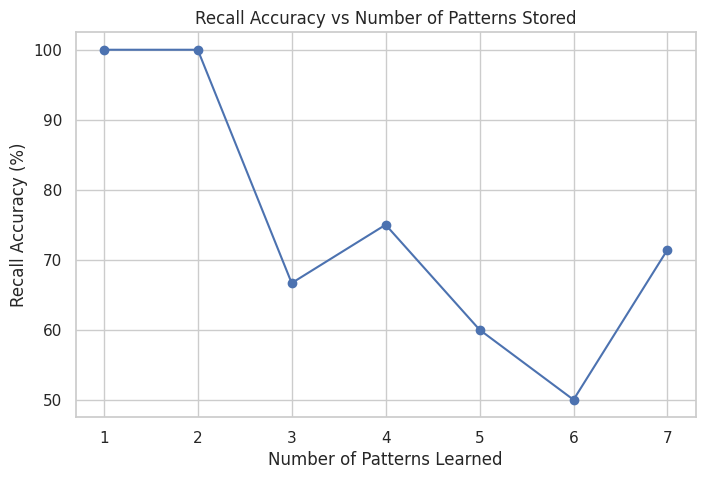

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def to_bipolar(pattern):
    return np.where(pattern == 0, -1, 1)

def bipolar_to_binary(pattern):
    return np.where(pattern == 1, 1, 0)

def recall_output(input_pattern, weight_matrix):
    net_input = np.dot(weight_matrix, input_pattern)
    bipolar_output = np.where(net_input >= 0, 1, -1)
    return bipolar_output

# Define all patterns upfront
inputs = np.array([[1, 0, 1, 0,],
                   [0, 1, 0, 1,],
                   [1, 1, 1, 0,],
                   [0, 0, 1, 1,], [1, 0, 0, 0,], [0, 0, 1, 0,],[1, 1, 1, 1,]])

outputs = np.array([[1, 1, 0, 0,],
                    [0, 0, 1, 1,],
                    [1, 0, 1, 1,],
                    [0, 1, 1, 0,], [1, 0, 1, 0,], [0, 0, 1, 0,], [0, 0, 1, 1,]])

inputs_bipolar = np.array([to_bipolar(p) for p in inputs])
outputs_bipolar = np.array([to_bipolar(p) for p in outputs])

def train_incremental_growing_verbose_show_patterns(inputs, inputs_bipolar, outputs, outputs_bipolar):
    N_out = outputs.shape[1]
    N_in = inputs.shape[1]
    W = np.zeros((N_out, N_in))
    accuracy = []

    for t in range(1, len(inputs)+1):
        W = np.zeros((N_out, N_in))  # Reset weights
        for i in range(t):
            W += np.outer(outputs_bipolar[i], inputs_bipolar[i])

        correct = 0
        failed_patterns = []
        for i in range(t):
            recalled = recall_output(inputs_bipolar[i], W)
            if np.array_equal(recalled, outputs_bipolar[i]):
                correct += 1
            else:
                failed_patterns.append(i)  # store index

        acc = correct / t * 100
        accuracy.append(acc)

        print(f"\nTrial {t}: Accuracy = {acc:.1f}%")
        if failed_patterns:
            print("Failed patterns:")
            for idx in failed_patterns:
                print(f" Pattern #{idx+1}:")
                print(f"  Input : {inputs[idx]}")
                print(f"  Output: {outputs[idx]}")
        else:
            print("No patterns failed.")

    return W, accuracy

# Run training and show failed patterns
W, accuracy = train_incremental_growing_verbose_show_patterns(inputs, inputs_bipolar, outputs, outputs_bipolar)

# Plotting accuracy
plt.figure(figsize=(8,5))
plt.plot(range(1, len(inputs)+1), accuracy, marker='o')
plt.xlabel("Number of Patterns Learned")
plt.ylabel("Recall Accuracy (%)")
plt.title("Recall Accuracy vs Number of Patterns Stored")
plt.grid(True)
plt.show()




In [ ]:
##17. What is the plot showing about memories encoded in a Hopfield matrix as more associations are learned?
##18. Why would the recall accuracy increase as more patterns are learned (from 3 to 4)?
##19. Add more associaitions into the matrix, how does this affected the recall accuracy? (try up to 7)
##20. What type of associations is it learning? Auto or hetero? What changes would need to be made to model the other type of associations not used here?




Trial 1: Accuracy = 100.0%
No patterns failed.

Trial 2: Accuracy = 50.0%
Failed patterns:
 Pattern #1:
  Input : [5 2 4 2]
  Output: [0 4 1 3]

Trial 3: Accuracy = 33.3%
Failed patterns:
 Pattern #2:
  Input : [1 3 2 3]
  Output: [2 4 2 4]
 Pattern #3:
  Input : [1 1 0 1]
  Output: [0 5 0 1]

Trial 4: Accuracy = 50.0%
Failed patterns:
 Pattern #2:
  Input : [1 3 2 3]
  Output: [2 4 2 4]
 Pattern #3:
  Input : [1 1 0 1]
  Output: [0 5 0 1]

Trial 5: Accuracy = 60.0%
Failed patterns:
 Pattern #1:
  Input : [5 2 4 2]
  Output: [0 4 1 3]
 Pattern #3:
  Input : [1 1 0 1]
  Output: [0 5 0 1]


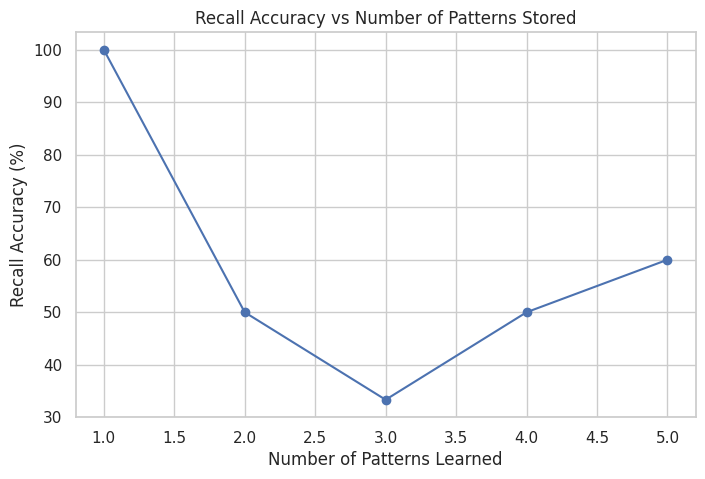

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Convert binary (0/1) pattern to bipolar (-1/1)
def to_bipolar(pattern):
    return np.where(pattern == 0, -1, 1)

# Convert bipolar (-1/1) back to binary (0/1) for printing
def bipolar_to_binary(pattern):
    return np.where(pattern == 1, 1, 0)

# Recall function: compute output given input and weight matrix
def recall_output(input_pattern, weight_matrix):
    net_input = np.dot(weight_matrix, input_pattern)
    bipolar_output = np.where(net_input >= 0, 1, -1)
    return bipolar_output

# Generate random binary patterns for inputs and outputs
def generate_random_patterns(num_patterns, input_size, output_size, seed=None):
    if seed is not None:
        np.random.seed(seed)  # for reproducibility

    inputs = np.random.randint(0, 6, size=(num_patterns, input_size))
    outputs = np.random.randint(0, 6, size=(num_patterns, output_size))
    return inputs, outputs

# Training with incremental growing pattern set
def train_incremental_growing_verbose_show_patterns(inputs, inputs_bipolar, outputs, outputs_bipolar, max_trials=None):
    if max_trials is None:
        max_trials = len(inputs)
    max_trials = min(max_trials, len(inputs))

    N_out = outputs.shape[1]
    N_in = inputs.shape[1]
    W = np.zeros((N_out, N_in))
    accuracy = []

    for t in range(1, max_trials + 1):
        W = np.zeros((N_out, N_in))  # Reset weights each trial
        for i in range(t):
            W += np.outer(outputs_bipolar[i], inputs_bipolar[i])

        correct = 0
        failed_patterns = []
        for i in range(t):
            recalled = recall_output(inputs_bipolar[i], W)
            if np.array_equal(recalled, outputs_bipolar[i]):
                correct += 1
            else:
                failed_patterns.append(i)

        acc = correct / t * 100
        accuracy.append(acc)

        print(f"\nTrial {t}: Accuracy = {acc:.1f}%")
        if failed_patterns:
            print("Failed patterns:")
            for idx in failed_patterns:
                print(f" Pattern #{idx+1}:")
                print(f"  Input : {inputs[idx]}")
                print(f"  Output: {outputs[idx]}")
        else:
            print("No patterns failed.")

    return W, accuracy

# ========== PARAMETERS ==========
num_patterns = 5     # Total number of patterns to generate and train on
input_size = 4        # Size of each input pattern
output_size = 4       # Size of each output pattern
random_seed = 123     # Seed for reproducibility

# Generate patterns
inputs, outputs = generate_random_patterns(num_patterns, input_size, output_size, seed=random_seed)

# Convert to bipolar
inputs_bipolar = np.array([to_bipolar(p) for p in inputs])
outputs_bipolar = np.array([to_bipolar(p) for p in outputs])

# Run training/testing
W, accuracy = train_incremental_growing_verbose_show_patterns(inputs, inputs_bipolar, outputs, outputs_bipolar, max_trials=num_patterns)

# Plot accuracy
plt.figure(figsize=(8,5))
plt.plot(range(1, num_patterns+1), accuracy, marker='o')
plt.xlabel("Number of Patterns Learned")
plt.ylabel("Recall Accuracy (%)")
plt.title("Recall Accuracy vs Number of Patterns Stored")
plt.grid(True)
plt.show()


In [ ]:
##21. This code chunk essetnially produces the same matrix, with less code. What is the differences between the 2?
##22. Which of the codes is more efficient? Which of the codes allows more user-specfied input and output?
##23. Add more patterns, change the input and output size, what trends do you notice?
##24. Can you think of a situation where you might use one versus the other?

## TURN IN FINAL CODE WITH ALL EDITS!